# Multiple Linear Regression:

In [ ]:
# import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [ ]:
sd=pd.read_csv('/content/Student_Performance.csv')
sd

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
...,...,...,...,...,...,...
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0


In [ ]:
sd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [ ]:
sd.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [ ]:
sd.tail()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0
9999,7,74,No,8,1,64.0


In [ ]:
#checking Null Values
sd.isnull().sum()

,0
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0


In [ ]:
#Check Duplicate Values
sd.duplicated().sum()

np.int64(127)

In [ ]:
sd=sd.drop_duplicates()

In [ ]:
sd.duplicated().sum()

np.int64(0)

In [ ]:
sd.shape

(9873, 6)

In [ ]:
sd.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9873 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     9873 non-null   int64  
 1   Previous Scores                   9873 non-null   int64  
 2   Extracurricular Activities        9873 non-null   object 
 3   Sleep Hours                       9873 non-null   int64  
 4   Sample Question Papers Practiced  9873 non-null   int64  
 5   Performance Index                 9873 non-null   float64
dtypes: float64(1), int64(4), object(1)
memory usage: 539.9+ KB


In [ ]:
#label encoding for object column - Extracurricular Activities
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
sd['Extracurricular Activities'] =le.fit_transform(sd['Extracurricular Activities'])


/tmp/ipykernel_563/3752877276.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sd['Extracurricular Activities'] =le.fit_transform(sd['Extracurricular Activities'])


In [ ]:
sd.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


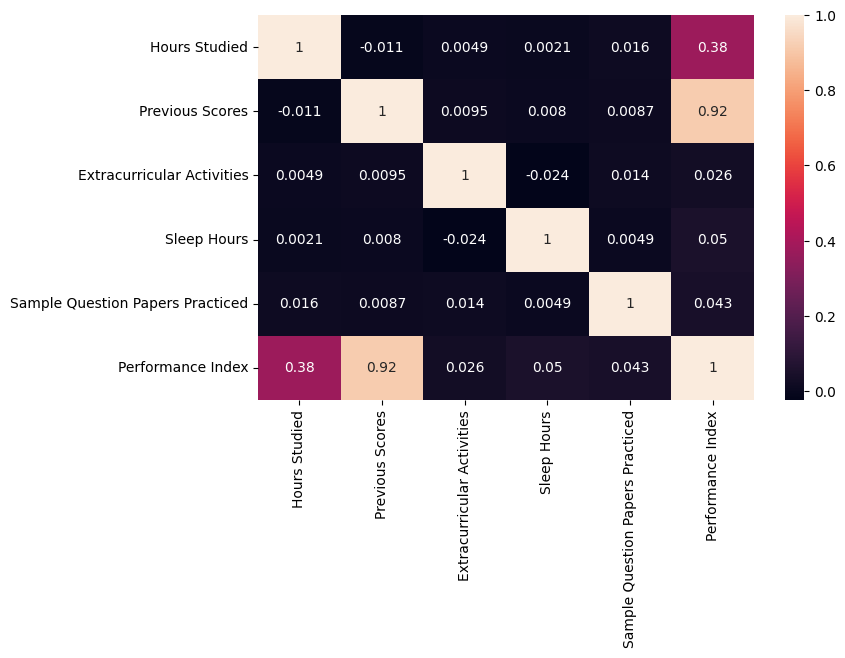

In [ ]:
##multi collinearity check using heat map
plt.figure(figsize=(8,5))
sns.heatmap(sd.corr(),annot=True)
plt.show()

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
col_list=[]
for i in sd.columns:
  if sd[i].dtype!='object' and i!='Performance Index':
    col_list.append(i)
x=sd[col_list]

vif_data=pd.DataFrame()
vif_data['Columns']= x.columns
vif_data['VIF_Score']=[variance_inflation_factor(x.values, i) for i in range(len(x.columns))]
vif_data

,Columns,VIF_Score
0,Hours Studied,1.000393
1,Previous Scores,1.000350
2,Extracurricular Activities,1.000888
3,Sleep Hours,1.000676
4,Sample Question Papers Practiced,1.000540


In [ ]:
#model Building
#train test split
x=sd.drop('Performance Index',axis=1)
y=sd['Performance Index']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
#model Build
model=LinearRegression()
model.fit(x_train,y_train)


LinearRegression()

In [ ]:
y_pred=model.predict(x_test)
y_pred

array([46.48001281, 80.2853795 , 61.06518835, ..., 77.08443628,
       86.24676576, 35.8793377 ])

In [ ]:
lr_values = pd.DataFrame({"Actual_value":y_test,"Predicted_value":y_pred})
lr_values

,Actual_value,Predicted_value
6099,47.0,46.480013
106,76.0,80.285379
9265,62.0,61.065188
4707,23.0,22.706315
2155,76.0,74.836868
...,...,...
8732,19.0,18.277835
3112,39.0,40.310084
5297,77.0,77.084436
6116,88.0,86.246766


In [ ]:
#Model Evaluation:
MSE=mean_squared_error(y_test,y_pred)
print("MSE:",MSE)
r2_score=r2_score(y_test,y_pred)
print("r2_score:",r2_score)

MSE: 4.305900938538479
r2_score: 0.9884301209927054
